In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/ncl-iot-team/CSC8112/main/data/PM2.5_labelled_data.csv"
df = pd.read_csv(url)

print(df.shape)
print(df.head())
print(df.columns.tolist())
print(df.iloc[:, -1].value_counts())

(1499, 7)
      Timestamp   Units Variable                Sensor Name  \
0  1.685580e+12  ugm -3    PM2.5  PER_AIRMON_MONITOR1135100   
1  1.685580e+12  ugm -3    PM2.5  PER_AIRMON_MONITOR1135100   
2  1.685580e+12  ugm -3    PM2.5  PER_AIRMON_MONITOR1135100   
3  1.685580e+12  ugm -3    PM2.5  PER_AIRMON_MONITOR1135100   
4  1.685580e+12  ugm -3    PM2.5  PER_AIRMON_MONITOR1135100   

   Flagged as Suspect Reading  Value Quality  
0                       False  4.273   GREEN  
1                       False  3.483   GREEN  
2                       False  3.713   GREEN  
3                       False  3.813   GREEN  
4                       False  3.885   GREEN  
['Timestamp', 'Units', 'Variable', 'Sensor Name', 'Flagged as Suspect Reading', 'Value', 'Quality']
Quality
GREEN     1027
YELLOW     461
RED         11
Name: count, dtype: int64


In [2]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

LABELS = ["GREEN", "YELLOW", "RED"]          # index 0, 1, 2
df = df.dropna(subset=["Value", "Quality"])
X = df[["Value"]].values.astype("float32")
y = df["Quality"].str.upper().map({l: i for i, l in enumerate(LABELS)}).values

# 80% training, 20% testing (har class ka ratio same rakhte hue)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Normalization layer: values ko ek standard scale pe laata hai
norm = tf.keras.layers.Normalization()
norm.adapt(X_train)

model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    norm,
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax"),
])
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# Class weights: kam aane wali class (RED) ko zyada importance
counts = np.bincount(y_train, minlength=3)
class_weight = {i: len(y_train) / (3 * c) for i, c in enumerate(counts)}
print("Class weights:", class_weight)

history = model.fit(X_train, y_train, validation_split=0.2, epochs=100,
                    batch_size=32, class_weight=class_weight, verbose=0)
print("Final training accuracy:", round(history.history["accuracy"][-1], 3))
model.summary()

Class weights: {0: np.float64(0.4868047097036135), 1: np.float64(1.0831074977416442), 2: np.float64(44.407407407407405)}
Final training accuracy: 0.997


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 1)              │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,070 (4.19 KB)

 Trainable params: 355 (1.39 KB)

 Non-trainable params: 3 (16.00 B)

 Optimizer params: 712 (2.79 KB)

Saved artifact at 'saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  137953167149968: TensorSpec(shape=(1, 1), dtype=tf.float32, name=None)
  137953167149392: TensorSpec(shape=(1, 1), dtype=tf.float32, name=None)
  137953167151120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137953167150736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137953167151696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137953167149584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137953167151888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137953167152656: TensorSpec(shape=(), dtype=tf.resource, name=None)
Keras: 32.4 KB | TFLite: 3.6 KB | 9.0x chhota


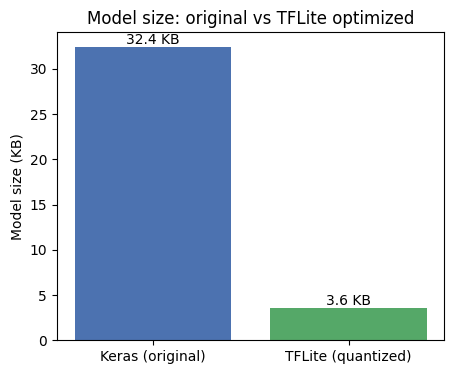

TFLite accuracy: 0.99


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [4]:
import os

# 1. Original Keras model save karo
model.save("pm25_model.keras")

# 2. TFLite mein convert karo, quantization ke saath
model.export("saved_model")
converter = tf.lite.TFLiteConverter.from_saved_model("saved_model")
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
with open("pm25_model.tflite", "wb") as f:
    f.write(tflite_model)

# 3. Size compare karo
keras_kb = os.path.getsize("pm25_model.keras") / 1024
tflite_kb = os.path.getsize("pm25_model.tflite") / 1024
print(f"Keras: {keras_kb:.1f} KB | TFLite: {tflite_kb:.1f} KB | {keras_kb / tflite_kb:.1f}x chhota")

plt.figure(figsize=(5, 4))
bars = plt.bar(["Keras (original)", "TFLite (quantized)"], [keras_kb, tflite_kb],
               color=["#4C72B0", "#55A868"])
plt.bar_label(bars, fmt="%.1f KB")
plt.ylabel("Model size (KB)")
plt.title("Model size: original vs TFLite optimized")
plt.savefig("model_size_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. TFLite model bhi test karo (same test data pe)
interp = tf.lite.Interpreter(model_path="pm25_model.tflite")
interp.allocate_tensors()
inp = interp.get_input_details()[0]
out = interp.get_output_details()[0]
tflite_pred = []
for x in X_test:
    interp.set_tensor(inp["index"], x.reshape(1, 1).astype(np.float32))
    interp.invoke()
    tflite_pred.append(int(interp.get_tensor(out["index"]).argmax()))
print("TFLite accuracy:", round(accuracy_score(y_test, tflite_pred), 3))

In [5]:
from google.colab import files
for f in ["pm25_model.tflite", "confusion_matrix.png", "model_size_comparison.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Accuracy: 0.99
              precision    recall  f1-score   support

       GREEN       1.00      1.00      1.00       206
      YELLOW       0.99      0.98      0.98        92
         RED       0.50      1.00      0.67         2

    accuracy                           0.99       300
   macro avg       0.83      0.99      0.88       300
weighted avg       0.99      0.99      0.99       300



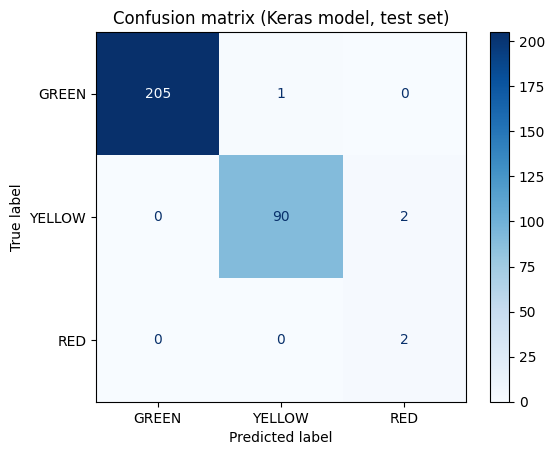

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, labels=[0, 1, 2],
                            target_names=LABELS, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap="Blues")
plt.title("Confusion matrix (Keras model, test set)")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
